# Ring trial

> Load the MIR spectra and soil properties of the soil spectroscopy ring trial of Safanelli et al. (2023)

In [ ]:
#| default_exp datasets.ringtrial

In [ ]:
#| export
from fastcore.all import *
import pandas as pd, numpy as np
from soilspecdata.types import *

In [ ]:
import matplotlib.pyplot as plt

In the ring trial of [Safanelli et al. (2023)](https://doi.org/10.1016/j.geoderma.2023.116724), 20 laboratories scanned the same 70 soil samples, each with its own MIR spectrometer and procedure. 60 samples are KSSL quality-control soils and 10 come from the North American Proficiency Testing (NAPT) program. The authors converted every spectrum to absorbance and resampled it from 650 to 4000 cm⁻¹ at a 2 cm⁻¹ step. The data also hold spectra of 59 of the samples from a Shimadzu instrument, under the name `Hokudai`.

The data are not public. `load_ringtrial` reads them from a local folder. The examples on this page read `data/ringtrial` in the soilspec workspace. `nbdev-test` skips them unless you run it with `--flags rtdata`.

In [ ]:
rt_path = Path('../../data/ringtrial')

## Spectra

In [ ]:
#| export
_preprocessings = ('raw', 'BOC', 'SG1stDer', 'SNV', 'SNVplusSG1stDer', 'SST') # Spectra files that `load_ringtrial` reads

def _find(
    path, # Folder to search, with its subfolders
    name, # File name
)->Path:
    "Path of the file `name` in `path` or its subfolders"
    fn = first(Path(path).rglob(name))
    if fn is None: raise FileNotFoundError(f"No {name} in {path}")
    return fn

def load_ringtrial(
    path, # Folder of the ring-trial files, searched with its subfolders
    preprocessing='raw', # Name of the spectra file to read, such as 'raw' or 'SNV'
)->dict: # `Spectra` of each instrument, keyed by its `organization` name
    "Load the ring-trial MIR spectra, one `Spectra` per instrument, with the soil properties as `source`"
    if preprocessing not in _preprocessings: raise ValueError(f"preprocessing must be one of {_preprocessings}, not {preprocessing!r}")
    props = pd.read_csv(_find(path, 'RT_wetchem_soildata.csv'), index_col='sample_id')
    df = pd.read_csv(_find(path, f'RT_STD_allMIRspectra_{preprocessing}.csv'))
    if preprocessing == 'raw': df = pd.concat([df, pd.read_csv(_find(path, 'shimadzu_spectra.csv'))])
    if preprocessing == 'SST': df = df[df.ct_subset == 'afterSST']
    cols = [c for c in df.columns if c.isdigit()]
    return {org: Spectra(np.array(cols, dtype=int), g[cols].to_numpy(), 'abs', g.sample_id.to_numpy(), source=props)
            for org, g in df.groupby('organization', sort=False)}

`load_ringtrial` returns a dictionary with one `Spectra` per instrument, keyed by the laboratory's `organization` name, such as `KSSL` or `IAEA_aug2022`. The same sample IDs, `RT_01` to `RT_70`, appear in every `Spectra`. They share one `source` table: the soil properties of `RT_wetchem_soildata.csv`, indexed by sample ID. Its `source` column says whether a sample comes from KSSL or NAPT.

`preprocessing` selects one of the spectra files of the paper:

- `raw`: absorbance, from 650 to 4000 cm⁻¹. Only this file includes `Hokudai`.
- `BOC`, `SG1stDer`, `SNV` and `SNVplusSG1stDer`: baseline offset correction, Savitzky-Golay first derivative, standard normal variate, and SNV then the derivative, from 660 to 3990 cm⁻¹.
- `SST`: the 20 test samples of the paper on the 19 instruments other than `KSSL`, after spectral space transformation towards `KSSL`, from 660 to 3990 cm⁻¹.

`load_ringtrial` searches `path` and its subfolders for each file, so the folder can keep the layout in which the files were shared.

In [ ]:
#| rtdata
rt = load_ringtrial(rt_path)
test_eq(len(rt), 21)
test_eq(rt['IAEA_aug2022'].spectra.shape, (70, 1676))
test_eq(len(rt['Hokudai'].sample_ids), 59)
list(rt)

['Agrocares',
 'Argonne',
 'CSU_IL',
 'ETH_alpha_1',
 'ETH_alpha_2',
 'ETH_vertex',
 'IAEA_aug2022',
 'KSSL',
 'LandCare',
 'Lesotho',
 'MSU',
 'OSU',
 'Rothamsted',
 'Scion',
 'UGhent',
 'UIUC',
 'USP',
 'UWisc_fine',
 'Woodwell_alpha',
 'Woodwell_vertex',
 'Hokudai']

`xy` reads the targets from `source`. On the IAEA instrument, 69 samples have both a spectrum and an exchangeable K value. Sample `RT_44` has no K value:


In [ ]:
#| rtdata
X, y, ids = rt['IAEA_aug2022'].xy('potassium_cmolkg')
test_eq(len(ids), 69)
X.shape, y.shape

((69, 1676), (69, 1))

Safanelli et al. found that most of the differences between the raw spectra of different instruments are baseline offsets. Here is sample `RT_19` on the KSSL Bruker Vertex 70, the IAEA Thermo Nicolet and the Shimadzu:


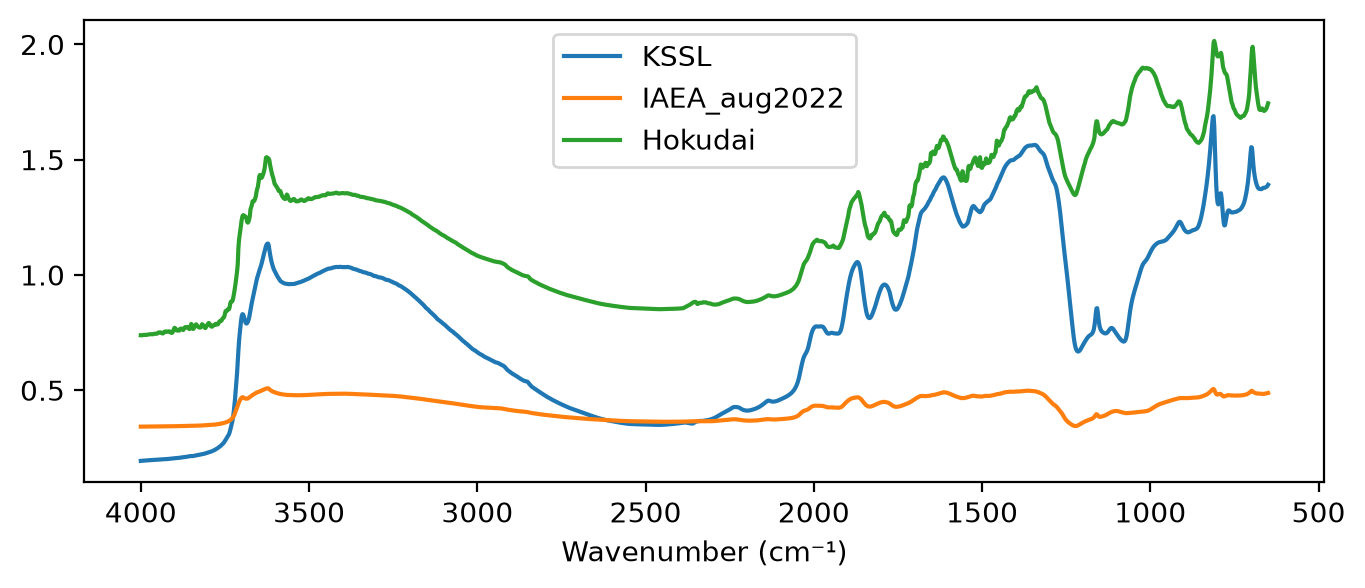

In [ ]:
#| rtdata
fig, ax = plt.subplots(figsize=(8, 3))
for org in ('KSSL', 'IAEA_aug2022', 'Hokudai'):
    s = rt[org]
    ax.plot(s.wavenumbers, s.spectra[list(s.sample_ids).index('RT_19')], label=org)
ax.invert_xaxis()
ax.set_xlabel('Wavenumber (cm⁻¹)')
ax.legend();

The `SST` file has no `KSSL` entry. `KSSL` is the instrument that the other spectra were transformed towards:

In [ ]:
#| rtdata
sst = load_ringtrial(rt_path, 'SST')
test_eq(len(sst), 19)
assert 'KSSL' not in sst
sst['IAEA_aug2022'].spectra.shape

(20, 1666)

`load_ringtrial` reads only the six files above. The paper also shared continuum-removed spectra (`CR`) with missing values, and wavelet coefficients (`wavelet`). Other names raise a `ValueError`:


In [ ]:
with expect_fail(contains='preprocessing must be one of'): load_ringtrial(rt_path, 'wavelet')
